# Lab 3: Uninformed Search (BFS & DFS)

---

## Learning Objectives

By the end of this lab, you will be able to:

1. Explain what a **search problem** is in AI (state space, initial state, actions, goal test).
2. Represent a search problem as a **graph**.
3. Understand and implement **Breadth-First Search (BFS)**.
4. Understand and implement **Depth-First Search (DFS)** (both iterative and recursive).
5. Compare BFS and DFS in terms of behavior, memory, and use-cases.

> **Note:** Heuristics, Greedy Best-First Search, and A* will be covered in the next lab (Informed Search).

## 1. What is a Search Problem?

An intelligent agent often needs to find a sequence of actions that takes it from a **start state** to a **goal state**. This is called a **search problem**.

A search problem is formally defined by:

- **State Space:** The set of all possible states the agent could be in.
- **Initial State:** Where the agent starts.
- **Actions / Successor Function:** What moves are possible from a given state, and what state they lead to.
- **Goal Test:** A way to check if a state is the goal.
- **Path Cost (optional for uninformed search):** The cost of a sequence of actions.

### Uninformed vs Informed Search

- **Uninformed (Blind) Search:** The agent has **no extra information** about how far a state is from the goal. It only knows the state space structure. *Examples: BFS, DFS.*
- **Informed Search:** The agent uses a **heuristic** an estimate of distance/cost to the goal to guide the search. *Examples: Greedy Best-First Search, A\*.* (Next lab!)


## 2. Representing the Search Space as a Graph

We represent the state space as a **graph**, where:

- Each **node** is a state.
- Each **edge** represents a valid action connecting two states.

We will use a simple **adjacency list** (a Python dictionary) to represent our graph, since it's easy to read and work with.

Below is a small example graph we will use throughout this notebook.

In [ ]:
# Graph represented as an adjacency list
# Key = node, Value = list of neighboring nodes (in the order we want to explore them)

graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F'],
    'D': ['B'],
    'E': ['B', 'F'],
    'F': ['C', 'E', 'G'],
    'G': ['F']
}

for node, neighbors in graph.items():
    print(f"{node} -> {neighbors}")

A -> ['B', 'C']
B -> ['A', 'D', 'E']
C -> ['A', 'F']
D -> ['B']
E -> ['B', 'F']
F -> ['C', 'E', 'G']
G -> ['F']


### Visualizing the Graph

Next we will draw this graph so it's easier to picture how BFS and DFS will move through it. This uses the `networkx` and `matplotlib` libraries.

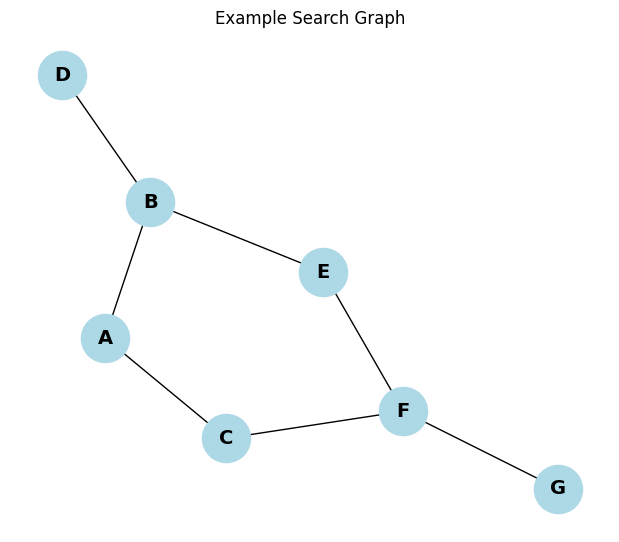

In [ ]:
# visualize the graph
# If networkx / matplotlib are not installed, run: pip install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
for node, neighbors in graph.items():
    for n in neighbors:
        G.add_edge(node, n)

plt.figure(figsize=(6, 5))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=1200, font_size=14, font_weight='bold')
plt.title("Example Search Graph")
plt.show()

## 3. Breadth-First Search (BFS)

 BFS explores the graph **level by level**. It first visits all neighbors of the start node, then all neighbors of those neighbors, and so on.


### BFS Algorithm (pseudocode)

```
BFS(graph, start):
    create a queue and enqueue start
    create a visited set and mark start as visited
    while queue is not empty:
        node = dequeue()
        process(node)
        for each neighbor of node:
            if neighbor not visited:
                mark neighbor as visited
                enqueue(neighbor)
```

Start:

Queue: [A]

Take A
Add B,C
Queue: [B,C]

Take B
Add D,E
Queue: [C,D,E]

Take C
Add F
Queue: [D,E,F]

Take D
No new nodes
Queue: [E,F]

Take E
F already visited
Queue: [F]

Take F
Add G
Queue: [G]

Take G
No new nodes
Queue: []

In [ ]:
from collections import deque

def bfs(graph, start):
    visited = set([start])
    queue = deque([start])
    order = []  # keeps track of the order in which nodes are visited

    while queue:
        node = queue.popleft()
        #what should we add here if we want to search a node?
        order.append(node)

        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return order

In [ ]:
# Run BFS starting from node 'A'
bfs_order = bfs(graph, 'A')
print("BFS Traversal Order:", bfs_order)

BFS Traversal Order: ['A', 'B', 'C', 'D', 'E', 'F', 'G']


### Practice Cell (BFS)

Try modifying the `bfs` function so that it also returns the **path** taken to reach a specific goal node (not just the visit order).

*Hint: keep a `parent` dictionary that records which node discovered each node, then reconstruct the path by walking backwards from the goal to the start.*


In [ ]:
# Your practice code here



## 4. Depth-First Search (DFS)

DFS explores as **deep as possible** along a branch before backtracking.

### DFS Algorithm (pseudocode)

```
DFS(graph, start):
    create a stack and push start
    create a visited set
    while stack is not empty:
        node = pop()
        if node not visited:
            mark node as visited
            process(node)
            push all unvisited neighbors of node
```

In [ ]:
def dfs_iterative(graph, start):
    visited = set()
    stack = [start]
    order = []

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.add(node)
            order.append(node)
            # Push neighbors in reverse so traversal order matches the adjacency list order
            for neighbor in reversed(graph[node]):
                if neighbor not in visited:
                    stack.append(neighbor)

    return order

In [ ]:
# Run iterative DFS starting from node 'A'
dfs_order = dfs_iterative(graph, 'A')
print("DFS (Iterative) Traversal Order:", dfs_order)

DFS (Iterative) Traversal Order: ['A', 'B', 'D', 'E', 'F', 'C', 'G']


### DFS — Recursive Version

DFS has a very natural **recursive** formulation, since recursion itself uses a call stack.

In [ ]:
def dfs_recursive(graph, node, visited=None, order=None):
    if visited is None:
        visited = set()
    if order is None:
        order = []

    visited.add(node)
    order.append(node)

    for neighbor in graph[node]:
        if neighbor not in visited:
            dfs_recursive(graph, neighbor, visited, order)

    return order

In [ ]:
# Run recursive DFS starting from node 'A'
dfs_rec_order = dfs_recursive(graph, 'A')
print("DFS (Recursive) Traversal Order:", dfs_rec_order)

DFS (Recursive) Traversal Order: ['A', 'B', 'D', 'E', 'F', 'C', 'G']


### Practice Cell (DFS)

Try tracing DFS **by hand** on paper for the graph above, starting from node `'C'` instead of `'A'`. Then run your traced version through the code below to check your answer.

In [ ]:
# Your practice code here
# e.g. dfs_iterative(graph, 'C')



## 5. BFS vs DFS — Comparison

| Feature | BFS | DFS |
|---|---|---|
| Data Structure | Queue (FIFO) | Stack (LIFO) / Recursion |
| Exploration Style | Level by level | Deep first, then backtrack |
| Complete? | Yes (finite branching) | Not always |
| Optimal? | Yes (equal edge costs) | No |
| Memory Usage | High (stores whole frontier) | Lower (stores single path) |
| Good for... | Shortest path in unweighted graphs | Exploring deep structures, when memory is limited |

### Quick Reflection Questions

1. If the goal node is very close to the start, which algorithm reaches it faster — BFS or DFS? Why?
2. If the graph is very wide (large branching factor) but shallow, which algorithm uses more memory?
3. Can DFS get "stuck" in an infinite loop? Under what condition, and how do we prevent it?